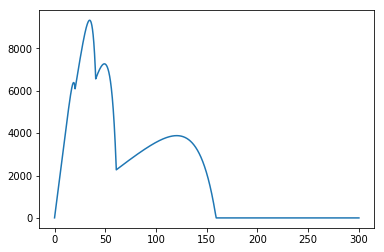

In [140]:
import numpy as np
import random
import matplotlib.pyplot as plt

class Shaded(object):
    def __init__(self):
        self.G = [100, 1000]  # read irradiance # Solar radiation in mW / sq.cm / Esto es la irradiancia para panel cuando [sombredo,sin_sombra]
        #self.T = 25  # read temperature # ojo con kelvin 273
        #self.SH = [4, 10, 7, 10, 10, 10]  # Shaded modules
        self.Mp = 10  # Modules in parallel
        self.Ng = [40, 38, 22]  # Parallel-connected series assemblies
        self.Iscr_sh = 0.375

    def data(self, Irradiancia_maxima, T, V, SH):

        # G_ar = np.array(G) # Solar radiation in mW/sq.cm

        pv = Panel()
        IUN = []
        ISH = []
        Ipv = []

        for j in range(len(self.Ng)):
            # IUN_i = pv.calc_pv(Irradiancia_maxima, T, V, SH[j*2])[0] # asi estaria bien hecho, pero como dejamos fija la irradiancia maxima lo tomamos del self.G[1]
            IUN_i = pv.calc_pv(self.G[1], T, V, SH[j*2])[0]
            if IUN_i < 0:
                IUN_i = 0
            IUN.append(IUN_i)
            ISH_i = pv.calc_pv(self.G[0], T, V, SH[j*2+1])[0]
            if ISH_i< 0:
                ISH_i = 0
            ISH.append(ISH_i)

        for jj in (range(len(self.Ng))):
            if IUN[jj] > self.Iscr_sh:
                Ipv.append(IUN[jj])
            else:
                Ipv.append(ISH[jj])

        
        IT = Ipv[0] * self.Ng[0] + Ipv[1] * self.Ng[1] + Ipv[2] * self.Ng[2]
        VT = V
        PT = IT*VT
        return IT, VT, PT 

class Panel(object):

    def __init__(self):
        self.TK = 273 # Kelvin temperature
        self.Tr1 = 40  # Reference temperature in degree fahrenheit
        # self.S = 100  # Solar radiation in mW / sq.cm
        self.ki = 0.00023  # in A / K
        self.Iscr = 3.75  # SC Current at ref.temp. in A
        self.Irr = 0.000021  # in A
        self.k = 1.38065e-23  # Boltzmann constant
        self.q = 1.6022e-19  # charge of an electron
        self.A = 2.15 # ideality factor
        self.Eg0 = 1.166 # band gap energy
        self.alpha = 0.473
        self.beta = 636
        # panel composed of Np parallel modules each one including Ns photovoltaic cells connected
        self.Np = 1
        self.Ns = 36

    def calc_pv(self, G, T, vx, SH):
        # cell temperature
        Tcell = T + self.TK
        # cell reference temperature in kelvin
        Tr = ((self.Tr1 - 32) * (5 / 9)) + 273
        # band gap energy of semiconductor
        Eg = self.Eg0 - (self.alpha * Tcell * Tcell) / (Tcell + self.beta) * self.q
        # generated photocurrent
        Iph = (self.Iscr + self.ki * (Tcell - Tr)) * (G / 1000)
        # cell reverse saturation current
        Irs = self.Irr * ((Tcell / Tr) ** 3) * np.exp(self.q * Eg / (self.k * self.A) * ((1 / Tr) - (1 / Tcell)))
        # panel output current
        I = self.Np * Iph - self.Np * Irs * (np.exp(self.q / (self.k * Tcell * self.A) * vx * (1/SH) / self.Ns) - 1)
        # panel output voltage
        V = vx # este es el Vg?
        # panel power
        P = vx * I

        return I,V,P

                
Voltage = 0.
Power = 0.
Temp = 25.
Irr = 1000.
# a = random.sample([1,2,3,4,5,6,7,8,9,10],1)[0]
# b = random.sample([1,2,3,4,5,6,7,8,9,10],1)[0]
# c = random.sample([1,2,3,4,5,6,7,8,9,10],1)[0]
a = 2
b = 3
c = 1
SH = [a, 10, b, 10, c, 10]

powerlst = []
voltagelst = []

for i in range(30000):
    Voltage += 0.01
    pv = Shaded()
    Current, Voltage, Power = pv.data(Irr, Temp, Voltage, SH)
    powerlst.append(Power)
    voltagelst.append(Voltage)

plt.plot(voltagelst, powerlst)

In [20]:
Vocnpy = np.zeros((11, 11, 11))
for i in range(1, 11):
    for j in range(1, 11):
        for k in range(1, 11):
            Voltage = 0.
            Power = 0.
            Temp = 25.
            Irr = 1000.
            a, b, c = i, j, k
            SH = [a, 10, b, 10, c, 10]
            Voc = 0
            for ite in range(212, -1, -1):
                Voltage = ite
                pv = Shaded()
                Current, Voltage, Power = pv.data(Irr, Temp, Voltage, SH)
                if Power > 0.0:
                    Voc = Voltage
                    break
            Vocnpy[i][j][k] = (Voc//10)
            print(i, j, k, Vocnpy[i][j][k])

1 1 1 15.0
1 1 2 15.0
1 1 3 15.0
1 1 4 15.0
1 1 5 15.0
1 1 6 15.0
1 1 7 15.0
1 1 8 16.0
1 1 9 18.0
1 1 10 20.0
1 2 1 15.0
1 2 2 15.0
1 2 3 15.0
1 2 4 15.0
1 2 5 15.0
1 2 6 15.0
1 2 7 15.0
1 2 8 16.0
1 2 9 18.0
1 2 10 20.0
1 3 1 15.0
1 3 2 15.0
1 3 3 15.0
1 3 4 15.0
1 3 5 15.0
1 3 6 15.0
1 3 7 15.0
1 3 8 16.0
1 3 9 18.0
1 3 10 20.0
1 4 1 15.0
1 4 2 15.0
1 4 3 15.0
1 4 4 15.0
1 4 5 15.0
1 4 6 15.0
1 4 7 15.0
1 4 8 16.0
1 4 9 18.0
1 4 10 20.0
1 5 1 15.0
1 5 2 15.0
1 5 3 15.0
1 5 4 15.0
1 5 5 15.0
1 5 6 15.0
1 5 7 15.0
1 5 8 16.0
1 5 9 18.0
1 5 10 20.0
1 6 1 15.0
1 6 2 15.0
1 6 3 15.0
1 6 4 15.0
1 6 5 15.0
1 6 6 15.0
1 6 7 15.0
1 6 8 16.0
1 6 9 18.0
1 6 10 20.0
1 7 1 15.0
1 7 2 15.0
1 7 3 15.0
1 7 4 15.0
1 7 5 15.0
1 7 6 15.0
1 7 7 15.0
1 7 8 16.0
1 7 9 18.0
1 7 10 20.0
1 8 1 16.0
1 8 2 16.0
1 8 3 16.0
1 8 4 16.0
1 8 5 16.0
1 8 6 16.0
1 8 7 16.0
1 8 8 16.0
1 8 9 18.0
1 8 10 20.0
1 9 1 18.0
1 9 2 18.0
1 9 3 18.0
1 9 4 18.0
1 9 5 18.0
1 9 6 18.0
1 9 7 18.0
1 9 8 18.0
1 9 9 18.0
1 9 10 20.0
1

9 9 8 18.0
9 9 9 18.0
9 9 10 20.0
9 10 1 20.0
9 10 2 20.0
9 10 3 20.0
9 10 4 20.0
9 10 5 20.0
9 10 6 20.0
9 10 7 20.0
9 10 8 20.0
9 10 9 20.0
9 10 10 20.0
10 1 1 20.0
10 1 2 20.0
10 1 3 20.0
10 1 4 20.0
10 1 5 20.0
10 1 6 20.0
10 1 7 20.0
10 1 8 20.0
10 1 9 20.0
10 1 10 20.0
10 2 1 20.0
10 2 2 20.0
10 2 3 20.0
10 2 4 20.0
10 2 5 20.0
10 2 6 20.0
10 2 7 20.0
10 2 8 20.0
10 2 9 20.0
10 2 10 20.0
10 3 1 20.0
10 3 2 20.0
10 3 3 20.0
10 3 4 20.0
10 3 5 20.0
10 3 6 20.0
10 3 7 20.0
10 3 8 20.0
10 3 9 20.0
10 3 10 20.0
10 4 1 20.0
10 4 2 20.0
10 4 3 20.0
10 4 4 20.0
10 4 5 20.0
10 4 6 20.0
10 4 7 20.0
10 4 8 20.0
10 4 9 20.0
10 4 10 20.0
10 5 1 20.0
10 5 2 20.0
10 5 3 20.0
10 5 4 20.0
10 5 5 20.0
10 5 6 20.0
10 5 7 20.0
10 5 8 20.0
10 5 9 20.0
10 5 10 20.0
10 6 1 20.0
10 6 2 20.0
10 6 3 20.0
10 6 4 20.0
10 6 5 20.0
10 6 6 20.0
10 6 7 20.0
10 6 8 20.0
10 6 9 20.0
10 6 10 20.0
10 7 1 20.0
10 7 2 20.0
10 7 3 20.0
10 7 4 20.0
10 7 5 20.0
10 7 6 20.0
10 7 7 20.0
10 7 8 20.0
10 7 9 20.0
10 7 10 20.

In [22]:
Vocnpy = Vocnpy.astype(int)
print(Vocnpy)

[[[ 0  0  0 ...  0  0  0]
  [ 0  0  0 ...  0  0  0]
  [ 0  0  0 ...  0  0  0]
  ...
  [ 0  0  0 ...  0  0  0]
  [ 0  0  0 ...  0  0  0]
  [ 0  0  0 ...  0  0  0]]

 [[ 0  0  0 ...  0  0  0]
  [ 0 15 15 ... 16 18 20]
  [ 0 15 15 ... 16 18 20]
  ...
  [ 0 16 16 ... 16 18 20]
  [ 0 18 18 ... 18 18 20]
  [ 0 20 20 ... 20 20 20]]

 [[ 0  0  0 ...  0  0  0]
  [ 0 15 15 ... 16 18 20]
  [ 0 15 15 ... 16 18 20]
  ...
  [ 0 16 16 ... 16 18 20]
  [ 0 18 18 ... 18 18 20]
  [ 0 20 20 ... 20 20 20]]

 ...

 [[ 0  0  0 ...  0  0  0]
  [ 0 16 16 ... 16 18 20]
  [ 0 16 16 ... 16 18 20]
  ...
  [ 0 16 16 ... 16 18 20]
  [ 0 18 18 ... 18 18 20]
  [ 0 20 20 ... 20 20 20]]

 [[ 0  0  0 ...  0  0  0]
  [ 0 18 18 ... 18 18 20]
  [ 0 18 18 ... 18 18 20]
  ...
  [ 0 18 18 ... 18 18 20]
  [ 0 18 18 ... 18 18 20]
  [ 0 20 20 ... 20 20 20]]

 [[ 0  0  0 ...  0  0  0]
  [ 0 20 20 ... 20 20 20]
  [ 0 20 20 ... 20 20 20]
  ...
  [ 0 20 20 ... 20 20 20]
  [ 0 20 20 ... 20 20 20]
  [ 0 20 20 ... 20 20 20]]]


In [131]:
Vocnpy[9][3][3]

18

In [136]:
ExplorCheckList = [0]*(Vocnpy[9][3][3] - 1)

In [137]:
print(ExplorCheckList)

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [138]:
len(ExplorCheckList)

17

0 2252.75 6.0
5.999
17.647058823529413
[1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

1 4505.04 12.0
11.999
35.294117647058826
[1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

2 6755.74 18.0
17.999
35.294117647058826
[1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

3 9001.16 24.0
23.999
52.94117647058824
[1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

4 11229.47 30.0
29.999
52.94117647058824
[1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

5 13403.57 36.0
35.999
70.58823529411765
[1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

6 15408.99 42.0
41.999
88.23529411764707
[1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

7 16896.89 48.0
47.999
88.23529411764707
[1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

8 16815.26 54.0
53.999
105.88235294117649
[1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

9 12018.62 60.0
59.999
105.88235294117649
[1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

10 11373.39 66.0
65.999
123.52941176470591
[1, 1, 1, 1, 1, 1,

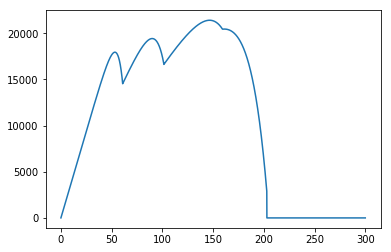

In [139]:
Voltage = 0.
Power = 0.
Temp = 25.
Irr = 1000.
a = 9
b = 3
c = 3
SH = [a, 10, b, 10, c, 10]

# powerlst = []
# voltagelst = []

reward = 0

for i in range(0, 300):
    Voltage += 6.0
    pv = Shaded()
    Current, Voltage, Power = pv.data(Irr, Temp, Voltage, SH)
#     powerlst.append(Power)
#     voltagelst.append(Voltage)
    print(i, round(Power,2), round(Voltage,1))

    
    
    
    tempVoltage = Voltage-0.001
    if len(ExplorCheckList) > int((tempVoltage//10)):
        if ExplorCheckList[int(tempVoltage//10)] == 0:
            ExplorCheckList[int(tempVoltage//10)] = 1
            reward = reward + 300/len(ExplorCheckList)
    
    print(tempVoltage)
    print(reward)
    print(ExplorCheckList)
    print()

plt.plot(voltagelst, powerlst)

In [105]:
9.999 // 10

0.0

In [44]:
10.0//10

1.0

In [45]:
20.0//10

2.0

In [98]:
np.round(9.99999, 3)

10.0

In [99]:
np.save('Voc.npy', Vocnpy)
# Pmax = np.load('Pmax.npy')